Import Required Libraries

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

Load the Three Images

In [2]:
print("Files in /content:")
print(os.listdir("/content"))

image_names = ["image-1", "image-2", "image-3"]
extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

images = {}

for name in image_names:
    path = None

    for ext in extensions:
        candidate = "/content/" + name + ext

        if os.path.exists(candidate):
            path = candidate
            break

    if path is None:
        print(f"{name} not found.")
        continue

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        images[name] = img
        print(f"{name} loaded: {img.shape}")

print("Total images loaded:", len(images))


Files in /content:
['.config', 'image-3.png', 'image-1.png', 'image-2.png', 'sample_data']
image-1 loaded: (226, 223)
image-2 loaded: (252, 270)
image-3 loaded: (259, 402)
Total images loaded: 3


Convert Images into Binary Format

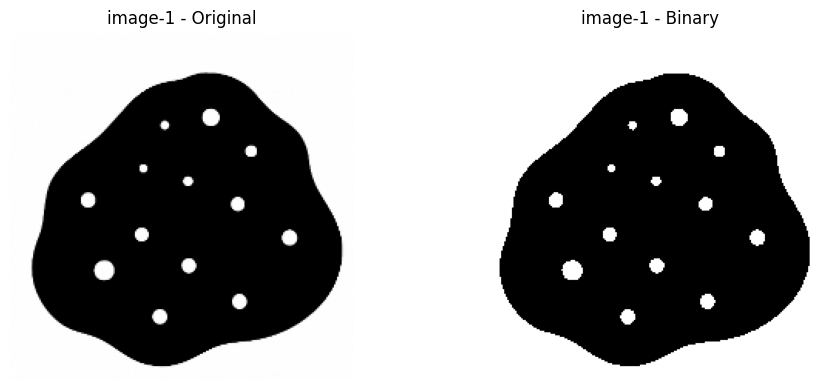

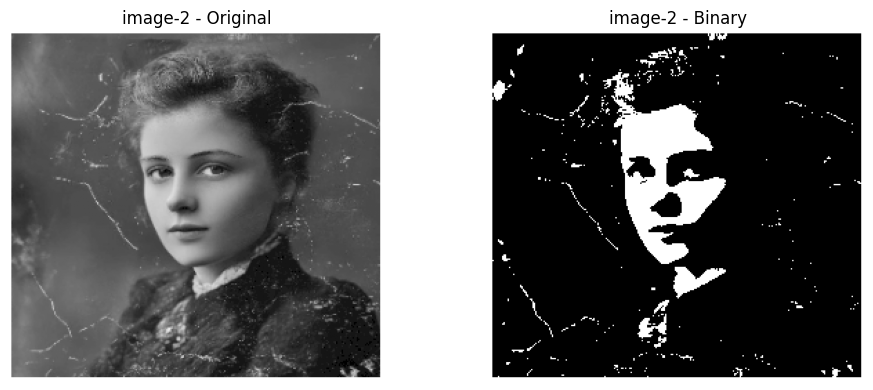

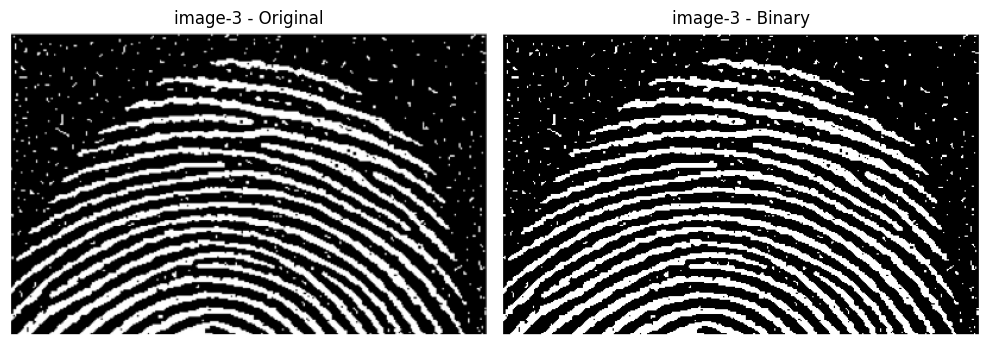

In [3]:

binary_images = {}

for name, img in images.items():

    _, binary = cv2.threshold(
        img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Ensure objects are white and background is black
    # Invert manually if the foreground is dark
    binary_images[name] = binary

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"{name} - Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(binary, cmap="gray")
    plt.title(f"{name} - Binary")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


Apply Dilation and Erosion Separately

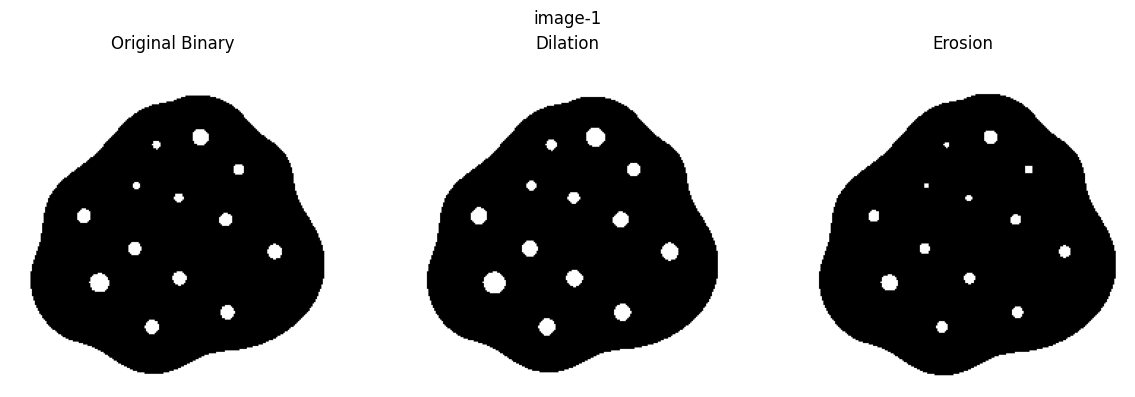

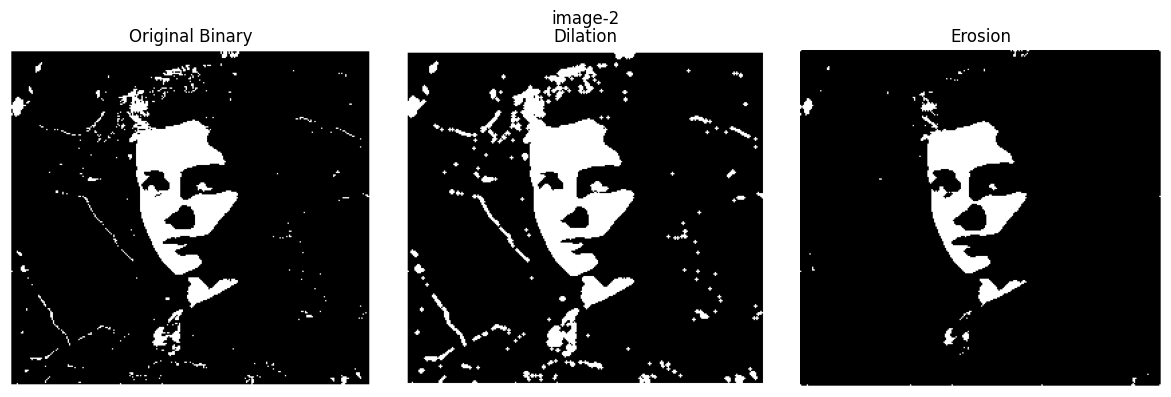

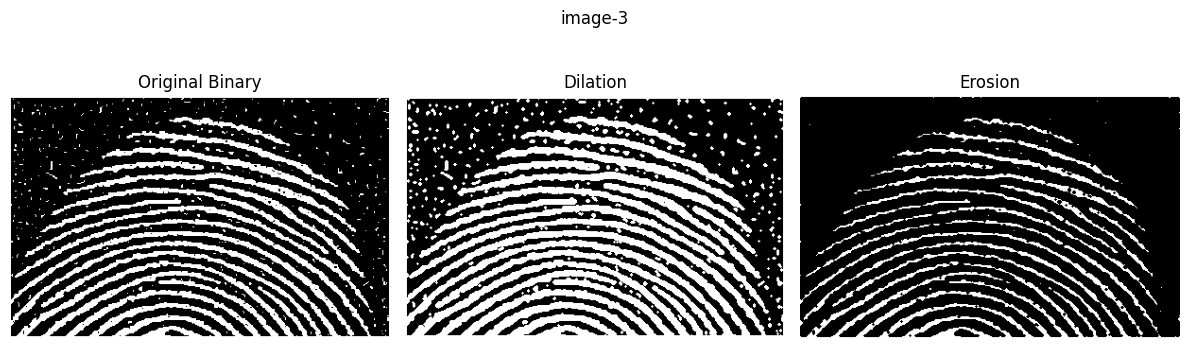

In [4]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

for name, binary in binary_images.items():

    dilated = cv2.dilate(
        binary, kernel, iterations=1
    )

    eroded = cv2.erode(
        binary, kernel, iterations=1
    )

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(binary, cmap="gray")
    plt.title("Original Binary")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(dilated, cmap="gray")
    plt.title("Dilation")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(eroded, cmap="gray")
    plt.title("Erosion")
    plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()


Apply Opening to Remove Bright Noise

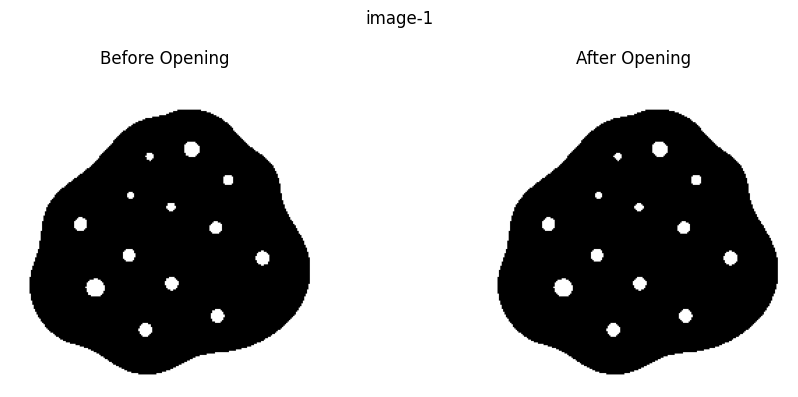

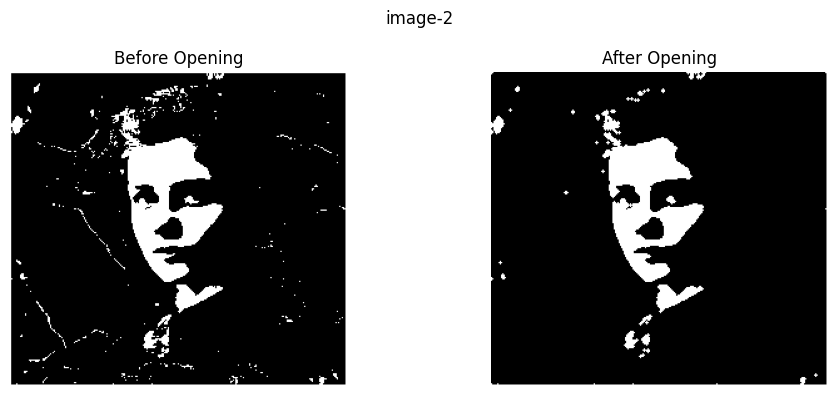

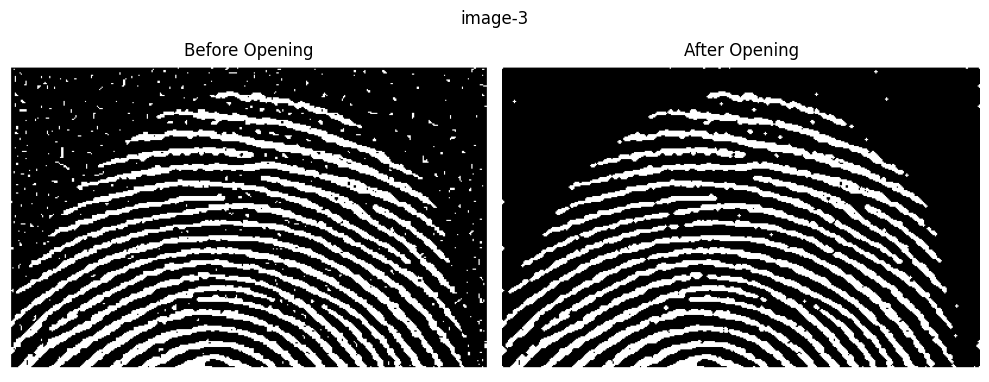

In [5]:

opened_images = {}

for name, binary in binary_images.items():

    opening = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

    opened_images[name] = opening

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(binary, cmap="gray")
    plt.title("Before Opening")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(opening, cmap="gray")
    plt.title("After Opening")
    plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()


Apply Closing to Fill Narrow Dark Cracks

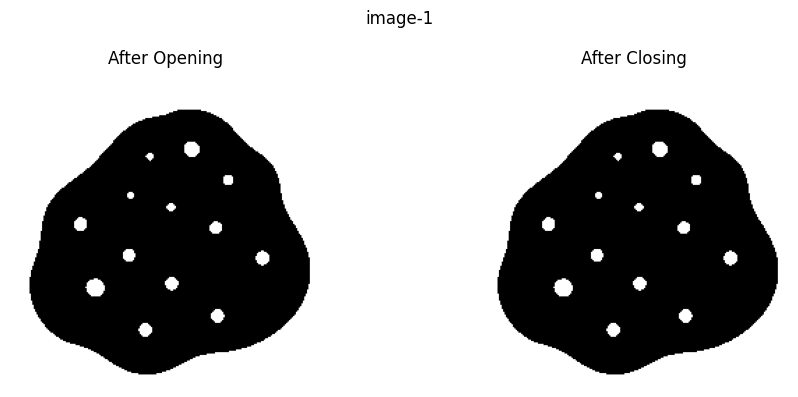

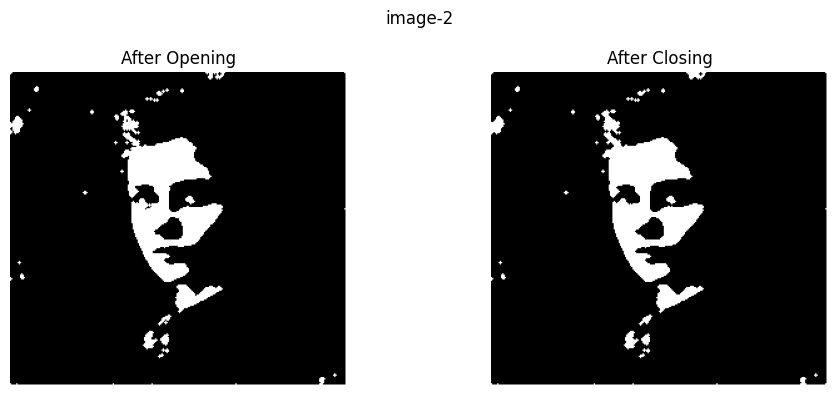

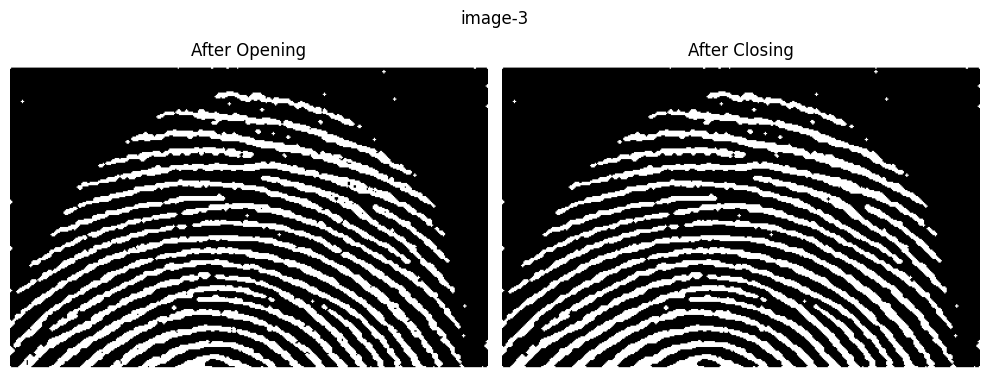

In [6]:

final_images = {}

for name, opened in opened_images.items():

    closing = cv2.morphologyEx(
        opened,
        cv2.MORPH_CLOSE,
        kernel
    )

    final_images[name] = closing

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(opened, cmap="gray")
    plt.title("After Opening")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(closing, cmap="gray")
    plt.title("After Closing")
    plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()


Compare the Complete Sequence

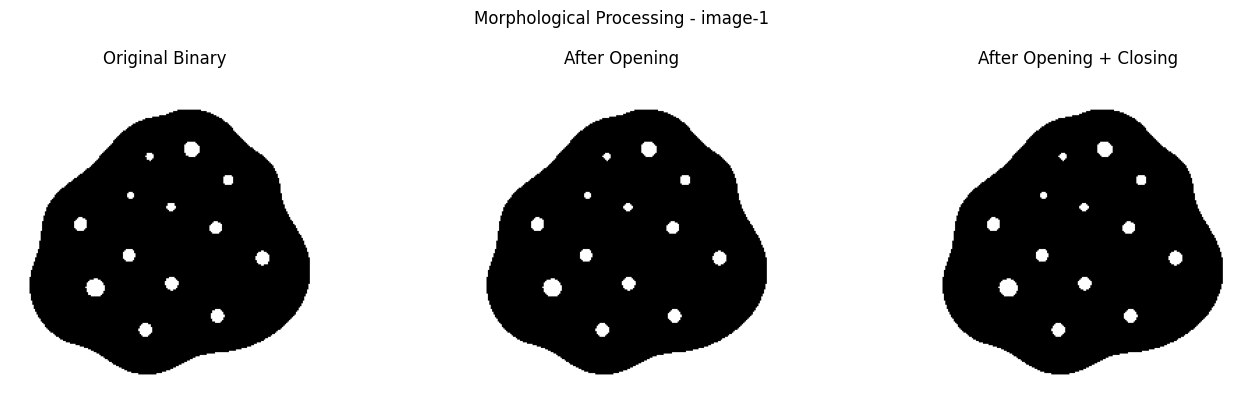

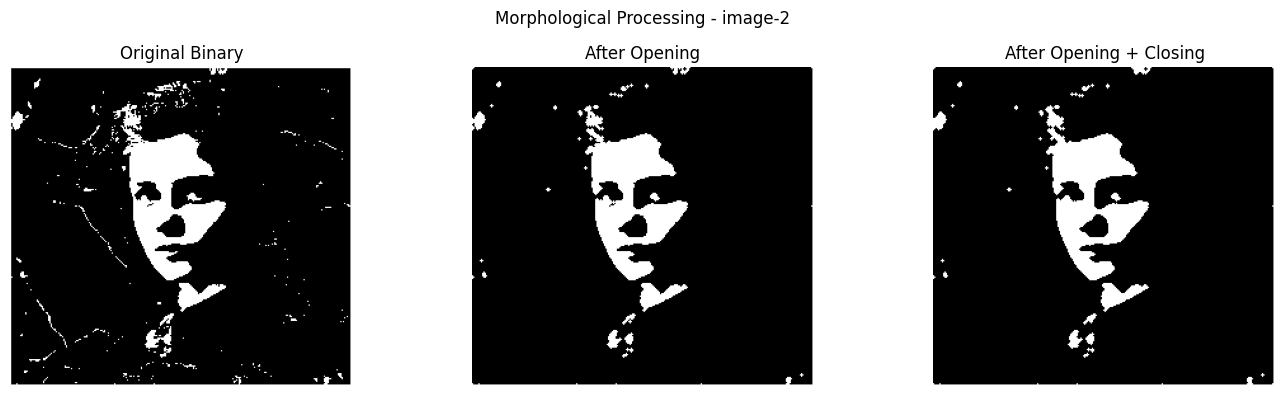

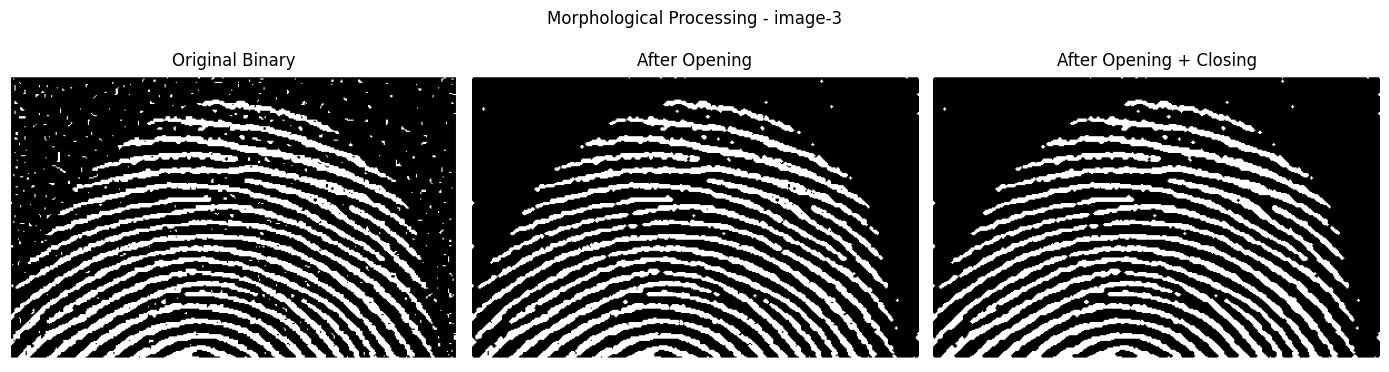

In [7]:

for name, binary in binary_images.items():

    opening = opened_images[name]
    final = final_images[name]

    plt.figure(figsize=(14, 4))

    titles = [
        "Original Binary",
        "After Opening",
        "After Opening + Closing"
    ]

    imgs = [binary, opening, final]

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(imgs[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(f"Morphological Processing - {name}")
    plt.tight_layout()
    plt.show()


Compare Different Kernel Sizes

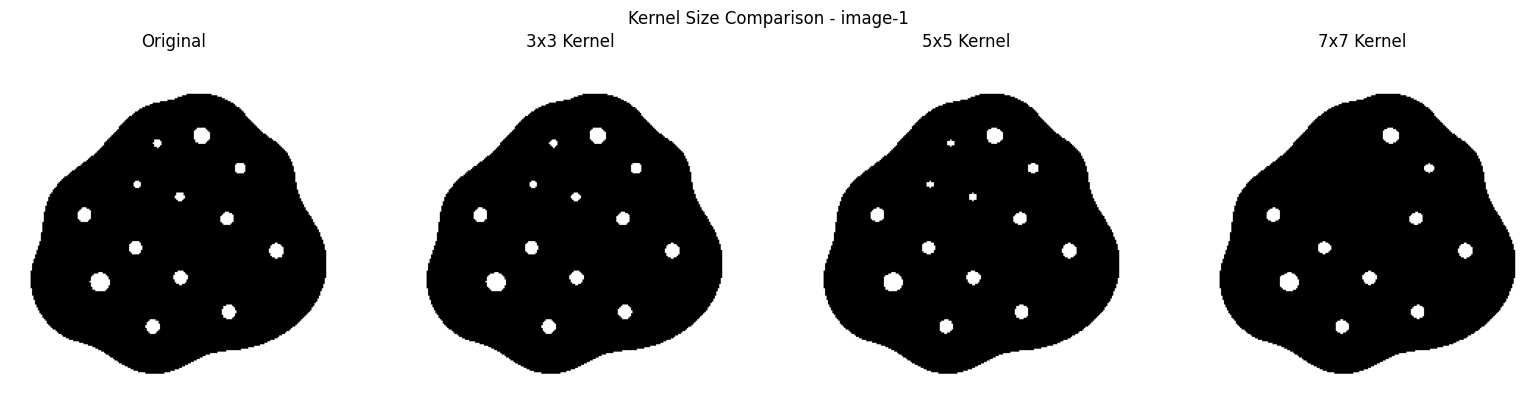

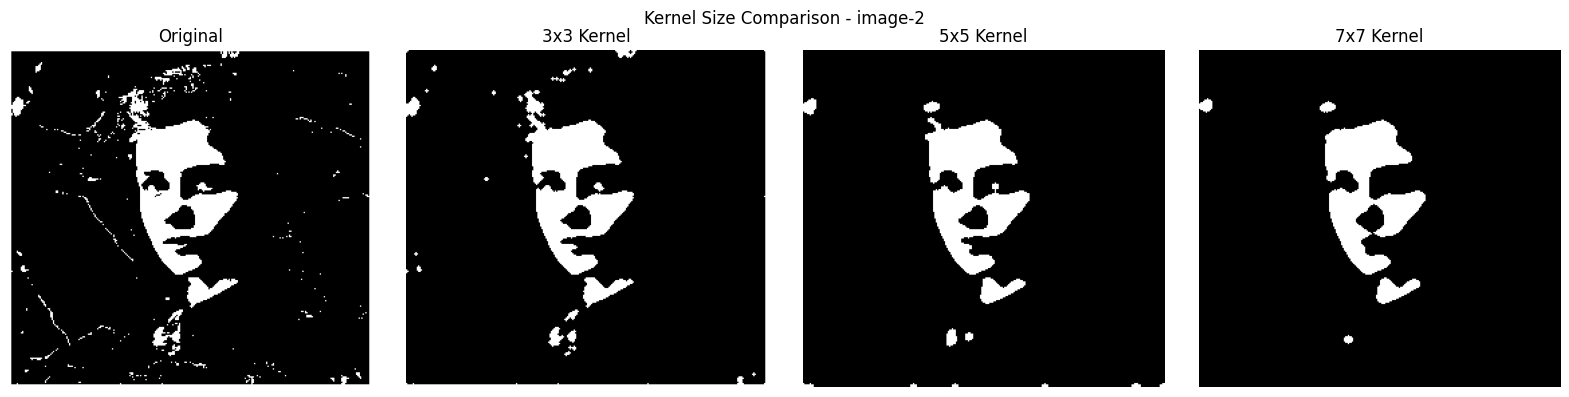

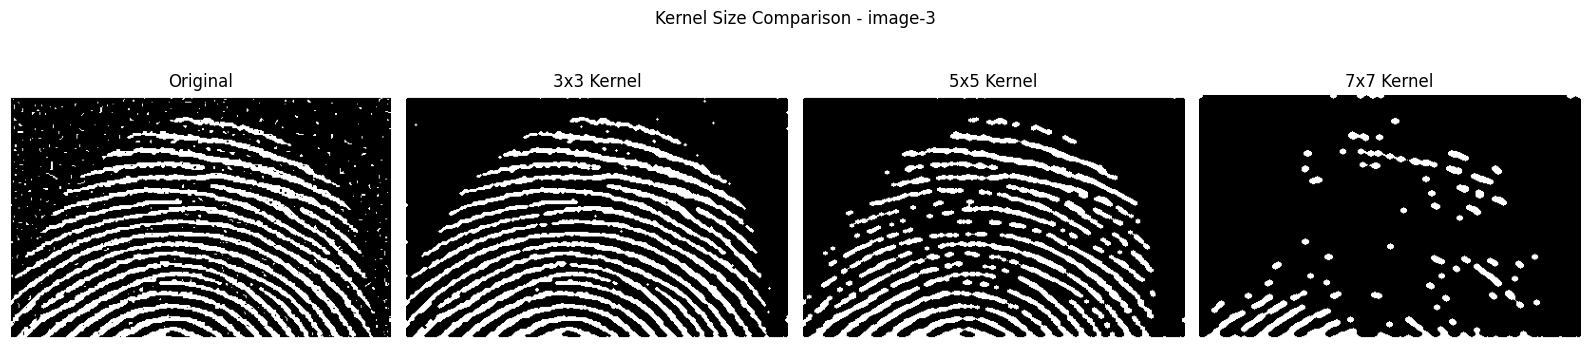

In [8]:

kernel_sizes = [3, 5, 7]

for name, binary in binary_images.items():

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(binary, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    for i, size in enumerate(kernel_sizes):

        k = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (size, size)
        )

        opening = cv2.morphologyEx(
            binary, cv2.MORPH_OPEN, k
        )

        closing = cv2.morphologyEx(
            opening, cv2.MORPH_CLOSE, k
        )

        plt.subplot(1, 4, i + 2)
        plt.imshow(closing, cmap="gray")
        plt.title(f"{size}x{size} Kernel")
        plt.axis("off")

    plt.suptitle(f"Kernel Size Comparison - {name}")
    plt.tight_layout()
    plt.show()


Compare Different Structuring Element Shapes

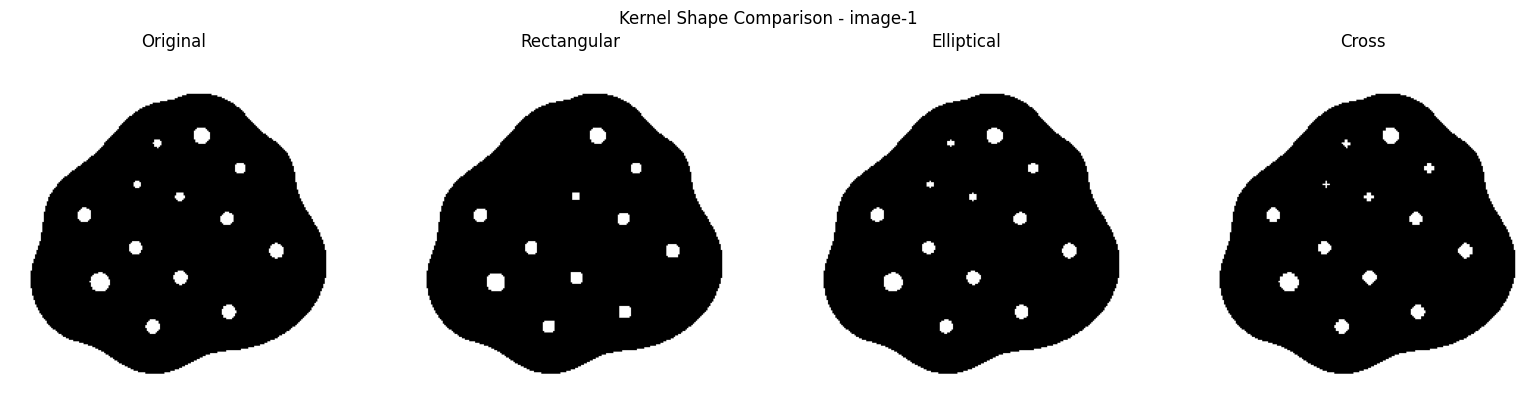

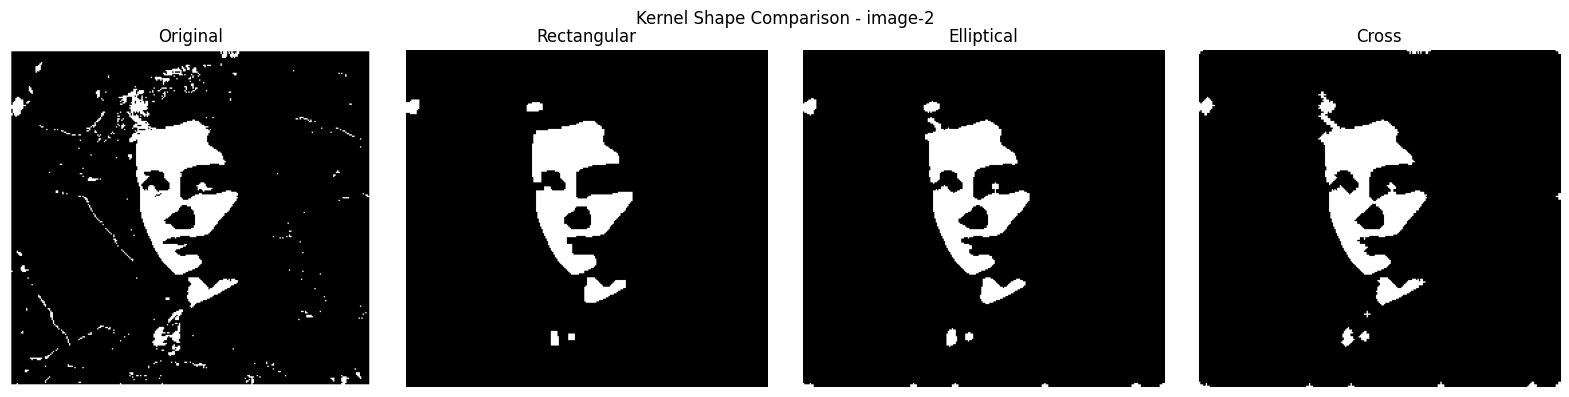

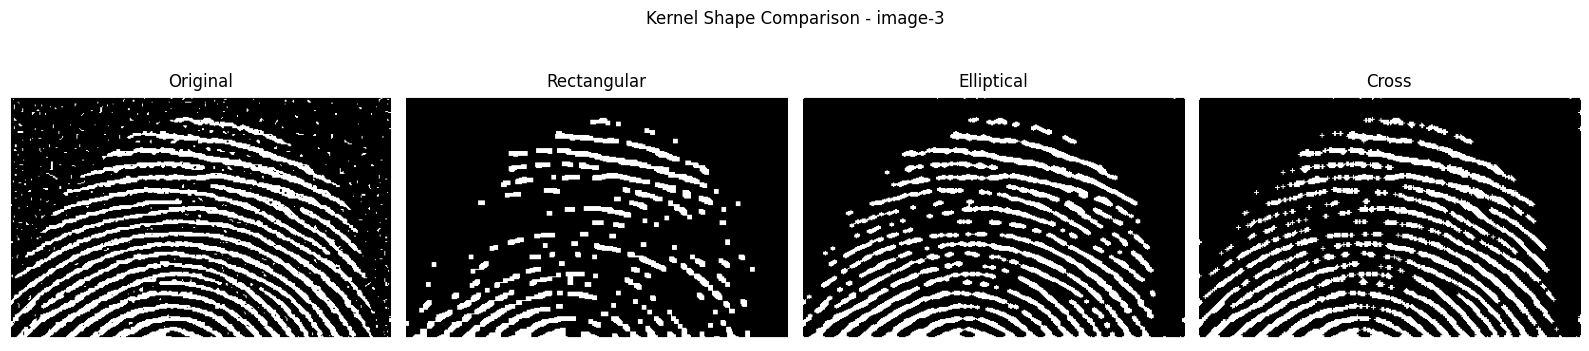

In [9]:

kernel_shapes = {
    "Rectangular": cv2.MORPH_RECT,
    "Elliptical": cv2.MORPH_ELLIPSE,
    "Cross": cv2.MORPH_CROSS
}

for name, binary in binary_images.items():

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(binary, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    for i, (shape_name, shape_type) in enumerate(
        kernel_shapes.items()
    ):

        k = cv2.getStructuringElement(
            shape_type, (5, 5)
        )

        opened = cv2.morphologyEx(
            binary, cv2.MORPH_OPEN, k
        )

        closed = cv2.morphologyEx(
            opened, cv2.MORPH_CLOSE, k
        )

        plt.subplot(1, 4, i + 2)
        plt.imshow(closed, cmap="gray")
        plt.title(shape_name)
        plt.axis("off")

    plt.suptitle(f"Kernel Shape Comparison - {name}")
    plt.tight_layout()
    plt.show()


Quantitative Analysis of Pixel Changes

In [10]:

analysis = []

for name, binary in binary_images.items():

    original_white = np.count_nonzero(binary)

    for size in [3, 5, 7]:

        k = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (size, size)
        )

        opened = cv2.morphologyEx(
            binary, cv2.MORPH_OPEN, k
        )

        final = cv2.morphologyEx(
            opened, cv2.MORPH_CLOSE, k
        )

        removed_pixels = np.count_nonzero(
            (binary == 255) & (opened == 0)
        )

        filled_pixels = np.count_nonzero(
            (opened == 0) & (final == 255)
        )

        changed_pixels = np.count_nonzero(
            binary != final
        )

        change_percent = (
            changed_pixels / binary.size
        ) * 100

        analysis.append({
            "Image": name,
            "Kernel": f"{size}x{size}",
            "Original White Pixels": original_white,
            "Pixels Removed by Opening": removed_pixels,
            "Pixels Added by Closing": filled_pixels,
            "Total Changed Pixels": changed_pixels,
            "Changed Pixels (%)": round(change_percent, 2)
        })

df = pd.DataFrame(analysis)

display(df)


,Image,Kernel,Original White Pixels,Pixels Removed by Opening,Pixels Added by Closing,Total Changed Pixels,Changed Pixels (%)
0,image-1,3x3,23650,11,0,11,0.02
1,image-1,5x5,23650,53,0,53,0.11
2,image-1,7x7,23650,133,0,133,0.26
3,image-2,3x3,7886,1300,67,1355,1.99
4,image-2,5x5,7886,2794,76,2842,4.18
5,image-2,7x7,7886,3155,87,3186,4.68
6,image-3,3x3,29969,2072,320,2346,2.25
7,image-3,5x5,29969,7409,776,7371,7.08
8,image-3,7x7,29969,22398,431,22353,21.47
